Applied Physics 155 - Lab 09

In [1]:
import numpy as np
import matplotlib.pyplot as plt

$PART A$

We first define the function f(x): $\frac{1}{1+25x^2}$

In [2]:
def f(x):
    return 1/(1+ 25*x**2)

We create a function for the test data points $(x_{j},y_{j})$ using the Chebyshev nodes.

In [3]:
def generatecheb(n,f,nodes="cheb"):
    if nodes=="cheb":
        dataxs = -np.cos(np.linspace(0,np.pi,n))
    else:
        dataxs = np.linspace(-1,1,n)
    datays= f(dataxs)
    return dataxs, datays

We create a function for the test data points $(x_{j},y_{j})$ using the linearly spaced nodes.

In [4]:
def generatelinear(n,f):
    dataxs = np.linspace(-1,1,n)
    datays= f(dataxs)
    return dataxs, datays

We define a function for the weight.

In [5]:
def weights(dataxs):
    n = dataxs.size
    ws = np.ones(n)
    for k in range(n):
        for j in range(n):
            if j == k:
                continue
            ws[k] *= (dataxs[k]-dataxs[j])
    return 1/ws

We create a function for p(x).

In [6]:
def p(dataxs, datays, ws, x):
    n = np.size(dataxs)
    L = np.ones(n)
    for k in range(n):
        for j in range(n):
            if j == k:
                continue
            L[k] *= (x - dataxs[j]) #this is the numerator
    Total = np.sum(datays*(L*ws))   #this evaluates the whole p(x)   
    return Total

This is the barycentric formula. We will use this to compare our answers with the function above.

In [7]:
def bary(dataxs,datays,ws,x):
    k = np.where(x == dataxs)[0]
    if k.size == 0:
        nume = np.sum(ws*datays/(x-dataxs))
        denom = np.sum(ws/(x-dataxs))
        val = nume/denom
    else:
        val = datays[k[0]]
    return val

Testing our function using the two formulas above at x = 0.3 and n = 20.

In [8]:
x = 0.3
dataxs1, datays1 = generatecheb(20,f, nodes="cheb")
ws = weights(dataxs1)
print(dataxs1, datays1)
print("-" * 60)
print(ws)
wobarry1 = p(dataxs1, datays1, ws, x)
wbarry1 = bary(dataxs1, datays1, ws, x)
print(" " );  print("Using Chebyshev Nodes:")
print("X value:", x); print("Without barycentric:",  wobarry1); print("With Barycentric:", wbarry1); print("f(x):", f(x)) 




#linearly spaced nodes
dataxs2, datays2 = generatelinear(20, f)
ws2 = weights(dataxs2)
wobarry2 = p(dataxs2, datays2, ws2, x)
wbarry2 = bary(dataxs2, datays2, ws2, x)
print(""); print("Using Linearly Spaced Nodes:")
print("X value:", x); print("Without barycentric:",  wobarry2); print("With Barycentric:", wbarry2); print("f(x):", f(x)) 




[-1.         -0.9863613  -0.94581724 -0.87947375 -0.78914051 -0.67728157
 -0.54694816 -0.40169542 -0.24548549 -0.08257935  0.08257935  0.24548549
  0.40169542  0.54694816  0.67728157  0.78914051  0.87947375  0.94581724
  0.9863613   1.        ] [0.03846154 0.03949024 0.04280042 0.04917182 0.06035524 0.08020688
 0.11794112 0.19864996 0.39895026 0.85434765 0.85434765 0.39895026
 0.19864996 0.11794112 0.08020688 0.06035524 0.04917182 0.04280042
 0.03949024 0.03846154]
------------------------------------------------------------
[ -6898.52631579  13797.05263158 -13797.05263158  13797.05263158
 -13797.05263158  13797.05263158 -13797.05263158  13797.05263158
 -13797.05263158  13797.05263158 -13797.05263158  13797.05263158
 -13797.05263158  13797.05263158 -13797.05263158  13797.05263158
 -13797.05263158  13797.05263158 -13797.05263158   6898.52631579]
 
Using Chebyshev Nodes:
X value: 0.3
Without barycentric: 0.2960749460796406
With Barycentric: 0.2960749460796406
f(x): 0.3076923076923077

Us

Using Chebyshev nodes, We see that indeed the barycentric formula and w/o the barycentric formula have the same result. However, using linearly spaced nodes, there is a big error.

We plot the result of the interpolation using the chebyshev and linear nodes combined.

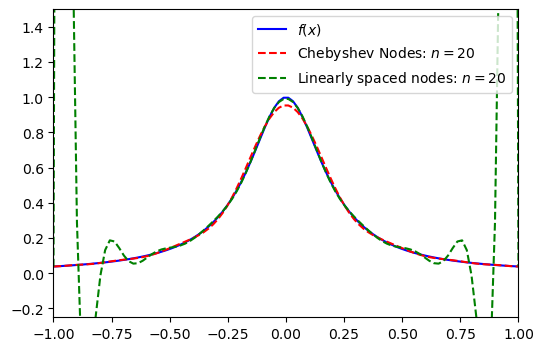

In [9]:
npoints = 100
wobarry1 = np.zeros(npoints)
wobarry2 = np.zeros(npoints)
xs=np.linspace(-1,1,npoints)
for j in range(npoints):
    wobarry1[j] = p(dataxs1, datays1, ws, xs[j])
    wobarry2[j] = p(dataxs2, datays2, ws2, xs[j])

fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlim(-1, 1)
ax.set_ylim(-0.25, 1.5)

ax.plot(xs,f(xs),linestyle='-', color='blue', label=r'$f(x)$')
ax.plot(xs,wobarry1,linestyle='--', color='red', label=r'Chebyshev Nodes: $n=20$')
ax.plot(xs,wobarry2,linestyle='--', color='green', label=r'Linearly spaced nodes: $n=20$')


ax.legend(loc='upper right')

plt.show()

$PART B$

We define our function $f(t)$. 

In [10]:
def func(t):
    return np.exp(-t)*np.cos(t)

This is for the n = 4. See that for this value of n, the interpolation is still not approximately the function.

In [11]:
x = 0.3
dataxs3, datays3 = generatecheb(4,func, nodes="cheb")
#dataxs3, datays3 = [generatecheb(n,func, nodes="cheb") for in n in range(7)]
ws3 = weights(dataxs3)
print(dataxs3, datays3)
print("-" * 60)
print(ws3)
wobarry3 = p(dataxs3, datays3, ws3, x)
wbarry3 = bary(dataxs3, datays3, ws3, x)
print(" " );  print("Using Chebyshev Nodes:")
print("X value:", x); print("Without barycentric:",  wobarry3); print("With Barycentric:", wbarry3); print("f(x):", func(x)) 





[-1.  -0.5  0.5  1. ] [1.46869394 1.44688904 0.53228073 0.19876611]
------------------------------------------------------------
[-0.66666667  1.33333333 -1.33333333  0.66666667]
 
Using Chebyshev Nodes:
X value: 0.3
Without barycentric: 0.7305541868586807
With Barycentric: 0.7305541868586808
f(x): 0.7077306780263507


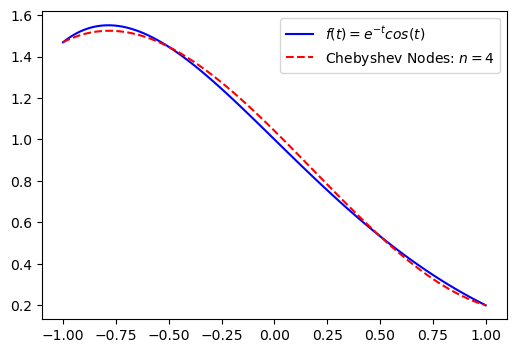

In [12]:
npoints = 100
wobarry3 = np.zeros(npoints)
#wbarry3 = np.zeros(npoints)
xs=np.linspace(-1,1,npoints)
for j in range(npoints):
    #wbarry3[j] = bary(dataxs3, datays3, ws3, xs[j])
    wobarry3[j] = p(dataxs3, datays3, ws3, xs[j])

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(xs,func(xs),linestyle='-', color='blue', label=r'$f(t) = e^{-t}cos(t)$')
ax.plot(xs,wobarry3,linestyle='--', color='red', label=r'Chebyshev Nodes: $n=4$')
#ax.plot(xs,wobarry3,linestyle='--', color='green', label=r'Linearly spaced nodes: $n=20$')


ax.legend(loc='upper right')

plt.show()

This is for the n = 5. See how starting from this value of n, the interpolation is approximately the function.

In [13]:
x = 0.3
dataxs3, datays3 = generatecheb(5,func, nodes="cheb")
#dataxs3, datays3 = [generatecheb(n,func, nodes="cheb") for in n in range(7)]
ws3 = weights(dataxs3)
print(dataxs3, datays3)
print("-" * 60)
print(ws3)
wobarry3 = p(dataxs3, datays3, ws3, x)
wbarry3 = bary(dataxs3, datays3, ws3, x)
print(" " );  print("Using Chebyshev Nodes:")
print("X value:", x); print("Without barycentric:",  wobarry3); print("With Barycentric:", wbarry3); print("f(x):", func(x)) 





[-1.00000000e+00 -7.07106781e-01 -6.12323400e-17  7.07106781e-01
  1.00000000e+00] [1.46869394 1.54186346 1.         0.37485281 0.19876611]
------------------------------------------------------------
[ 1. -2.  2. -2.  1.]
 
Using Chebyshev Nodes:
X value: 0.3
Without barycentric: 0.7042701473012108
With Barycentric: 0.704270147301211
f(x): 0.7077306780263507


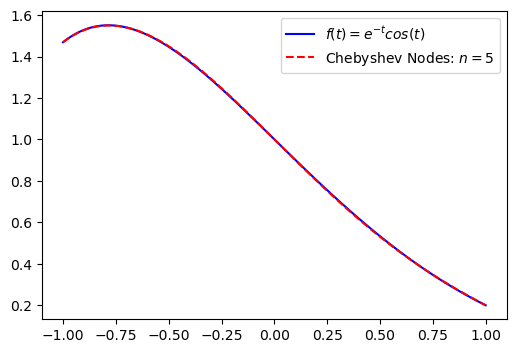

In [14]:
npoints = 100
wobarry3 = np.zeros(npoints)
#wbarry3 = np.zeros(npoints)
xs=np.linspace(-1,1,npoints)
for j in range(npoints):
    #wbarry3[j] = bary(dataxs3, datays3, ws3, xs[j])
    wobarry3[j] = p(dataxs3, datays3, ws3, xs[j])

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(xs,func(xs),linestyle='-', color='blue', label=r'$f(t) = e^{-t}cos(t)$')
ax.plot(xs,wobarry3,linestyle='--', color='red', label=r'Chebyshev Nodes: $n=5$')
#ax.plot(xs,wobarry3,linestyle='--', color='green', label=r'Linearly spaced nodes: $n=20$')


ax.legend(loc='upper right')

plt.show()

Note that the range x ∈ [-1,1] is the only one present in the graph. Moreover, by trial and error and changing the number of nodes in the generatecheb function, the interpolation starts to be approximately the given function at 5 nodes. 